# Optimal Transport Between Cat and Dog Feature Distributions

## 1. Problem setup

Let $\mathcal{X}$ denote the space of images. We assume that cat and dog images are sampled from two unknown probability distributions:

$$
X_c \sim P_c, \qquad X_d \sim P_d.
$$

### Both classes are latent mixtures

CIFAR-10 provides only the coarse labels "cat" and "dog." It does not identify breed, image source, camera, background, or the other processes that produced an image. We therefore should not assume that either class comes from one breed or one homogeneous source.

Let $Z_c$ and $Z_d$ collect the unavailable latent factors for each class. The observed class distributions are aggregate mixtures

$$
P_c=\int P(X\mid Y=c,Z_c=z)\,d\rho_c(z),
\qquad
P_d=\int P(X\mid Y=d,Z_d=z)\,d\rho_d(z),
$$

where $\rho_c$ and $\rho_d$ are unknown mixing distributions. These expressions include discrete mixtures over breeds as a special case, but they also allow continuous nuisance factors such as pose, lighting, and compression.

Accordingly, there is no universal cat distribution or dog distribution. The notation $P_c$ and $P_d$ refers to the marginal distributions induced by the particular dataset and sampling procedure being studied. Their supports may contain several modes or manifold components rather than one class manifold.

Because the latent variables are unobserved, their components are not identifiable from the binary labels alone. OT can nevertheless be computed between the observed aggregate empirical measures $\widehat P_c$ and $\widehat P_d$. The resulting coupling reflects both the semantic class difference and differences in dataset composition.

### Connection to human and AI-generated images

The same structure applies to binary human-versus-AI image detection. Human images can originate from different cameras, platforms, editing pipelines, content domains, and collection procedures. AI images can additionally originate from different generator families, versions, prompts, and post-processing pipelines. Neither side is a single homogeneous population.

Let $S_H$ and $S_A$ denote these unavailable source factors. For a particular collected dataset, define

$$
P_H=\int P(X\mid Y=H,S_H=s)\,d\rho_H(s),
$$

$$
P_A=\int P(X\mid Y=A,S_A=s)\,d\rho_A(s).
$$

Generator identity can be included as one component of $S_A$, but no generator or source labels are assumed to be available. The observed data provide only the binary class label $Y\in\{H,A\}$.

Thus, the practical OT problem compares aggregate, dataset-dependent measures $P_H$ and $P_A$, analogous to comparing aggregate CIFAR-10 measures $P_c$ and $P_d$. Without additional metadata or assumptions, OT cannot recover the latent source distributions separately.

## 2. Feature-space distributions

Computing transport directly in pixel space is unlikely to reflect semantic similarity. Instead, let

$$
\phi_\theta:\mathcal{X}\rightarrow\mathbb{R}^{1280}
$$

be the representation produced by the CLS token of the fine-tuned DINOv3 encoder. The model uses a DINOv3 ViT-H+/16 backbone, a linear $1280\rightarrow2$ classification head, and an independent linear $1280\rightarrow2$ localization head applied to each patch token.

We define the pushforward feature distributions

$$
\mu_c=(\phi_\theta)_\#P_c,
\qquad
\mu_d=(\phi_\theta)_\#P_d.
$$

Thus, $\mu_c$ and $\mu_d$ describe where the aggregate cat and dog populations lie in the learned representation space. Both remain latent mixtures after applying the encoder. For $y\in\{c,d\}$,

$$
\mu_y
=
(\phi_\theta)_\#P_y
=
\int (\phi_\theta)_\#P(X\mid Y=y,Z_y=z)\,d\rho_y(z).
$$

Analogously, both available human and AI feature distributions are aggregate mixtures:

$$
\mu_H
=
(\phi_\theta)_\#P_H
=
\int (\phi_\theta)_\#P(X\mid Y=H,S_H=s)\,d\rho_H(s),
$$

$$
\mu_A
=
(\phi_\theta)_\#P_A
=
\int (\phi_\theta)_\#P(X\mid Y=A,S_A=s)\,d\rho_A(s).
$$

These definitions require neither breed labels nor human/AI source labels. Aggregate OT cannot determine which latent process produced an individual sample; it only compares the observed mixtures.

Given samples $\{x_i^c\}_{i=1}^{n}$ and $\{x_j^d\}_{j=1}^{m}$, their empirical feature distributions are

$$
\widehat\mu_c=\sum_{i=1}^{n}a_i\delta_{z_i^c},
\qquad
\widehat\mu_d=\sum_{j=1}^{m}b_j\delta_{z_j^d},
$$

where

$$
z_i^c=\phi_\theta(x_i^c),
\qquad
z_j^d=\phi_\theta(x_j^d),
$$

and, for uniformly weighted samples, $a_i=1/n$ and $b_j=1/m$.

## 3. Transport cost

After L2-normalizing the feature vectors, a simple semantic transport cost is cosine distance:

$$
C_{ij}=c(z_i^c,z_j^d)=1-\langle z_i^c,z_j^d\rangle.
$$

Other costs could later incorporate patch-token geometry or localization information, but CLS-token cosine distance provides a simple v1.

## 4. Entropic optimal transport

Let

$$
\Pi(a,b)=\left\{\pi\in\mathbb{R}_{+}^{n\times m}:\pi\mathbf{1}_m=a,\;\pi^\top\mathbf{1}_n=b\right\}
$$

be the set of couplings between the empirical cat and dog distributions. The entropically regularized transport problem is

$$
\operatorname{OT}_\varepsilon(\widehat\mu_c,\widehat\mu_d)
=
\min_{\pi\in\Pi(a,b)}
\sum_{i,j}\pi_{ij}C_{ij}
+
\varepsilon\sum_{i,j}\pi_{ij}(\log\pi_{ij}-1).
$$

The optimal coupling $\pi^*$ represents a soft matching between cat and dog samples. A large value of $\pi^*_{ij}$ means that the model regards cat image $i$ and dog image $j$ as relatively similar under the chosen feature-space cost.

For a less biased comparison between distributions, we can use the Sinkhorn divergence

$$
S_\varepsilon(\mu_c,\mu_d)
=
\operatorname{OT}_\varepsilon(\mu_c,\mu_d)
-\frac{1}{2}\operatorname{OT}_\varepsilon(\mu_c,\mu_c)
-\frac{1}{2}\operatorname{OT}_\varepsilon(\mu_d,\mu_d).
$$

## 5. Cat-to-dog and dog-to-cat maps

When the cost is symmetric, the OT distance itself has no direction. Direction becomes meaningful when constructing barycentric transport maps. The cat-to-dog map is

$$
T_{c\rightarrow d}(z_i^c)
=
\frac{\sum_j\pi^*_{ij}z_j^d}{\sum_j\pi^*_{ij}},
$$

and the corresponding dog-to-cat map is

$$
T_{d\rightarrow c}(z_j^d)
=
\frac{\sum_i\pi^*_{ij}z_i^c}{\sum_i\pi^*_{ij}}.
$$

These maps describe movement in feature space; they do not by themselves generate valid images.

## 6. Robustness objective

Directly minimizing the distance between cat and dog distributions would collapse class information and could weaken the classifier. For robustness to distribution shift, a more suitable objective is class-conditional alignment. If $\mu_y^{\mathrm{train}}$ and $\mu_y^{\mathrm{target}}$ denote the training and target-domain feature distributions for class $y\in\{c,d\}$, then an alignment term is

$$
\mathcal{L}_{\mathrm{align}}
=
S_\varepsilon(\mu_c^{\mathrm{train}},\mu_c^{\mathrm{target}})
+
S_\varepsilon(\mu_d^{\mathrm{train}},\mu_d^{\mathrm{target}}).
$$

The human–AI analogue replaces $c,d$ with $H,A$. This objective requires only binary human/AI labels for the alignment data; it does not require labels identifying the AI generator. If even binary labels are unavailable in the target domain, this class-conditional objective cannot be computed directly without pseudo-labels or another unsupervised assumption.

This aligns cats with cats and dogs with dogs across domains while retaining the distinction between the two classes. A v1 can therefore use normalized CLS features, cosine transport cost, entropic regularization, and class-conditional Sinkhorn divergence over the aggregate class distributions. Patch-level or latent-generator-aware transport can be considered later if additional metadata becomes available.


# CIFAR-10 cat–dog experiment

CIFAR-10 provides cat and dog labels but no breed or source annotations. The experiment therefore treats both classes as aggregate empirical mixtures. This matches the human–AI setting, where neither the origins of the human images nor the generator identities of the AI images are assumed to be available.

The cells below deliberately separate three concerns:

1. selecting cat and dog images from CIFAR-10;
2. obtaining normalized CLS features from a user-supplied model;
3. computing the Sinkhorn coupling and barycentric feature maps.

The experiment uses `timm`'s smallest available DINOv3 ViT architecture, `vit_tiny_patch16_dinov3_qkvb`, with `pretrained=False`. This DINOv3-specific variant has approximately 5.49 million parameters and 192-dimensional CLS features; it is distinct from the generic `vit_tiny_patch16_224` model used previously. It is initialized randomly and then trained as a binary cat–dog classifier before its CLS features are used for OT. Replace this model with the fine-tuned production model for the real experiment.

In [4]:
import math
from dataclasses import dataclass
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import timm
import torch
import torch.nn.functional as F
from torch import Tensor, nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms


def resolve_local_data_root() -> Path:
    """Find an existing local data/cifar-10-batches-py directory."""
    for parent in (Path.cwd(), *Path.cwd().parents):
        candidate = parent / "data"
        if (candidate / "cifar-10-batches-py").is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        "Expected an extracted CIFAR-10 dataset under a local data/ directory."
    )


LOCAL_DATA_ROOT = resolve_local_data_root()


@dataclass(frozen=True)
class ExperimentConfig:
    data_root: Path = LOCAL_DATA_ROOT
    samples_per_class: int = 256
    batch_size: int = 32
    train_batch_size: int = 64
    image_size: int = 224  # multiple of the model's 16-pixel patch size
    epochs: int = 3
    learning_rate: float = 3e-4
    weight_decay: float = 0.05
    epsilon: float = 0.05
    sinkhorn_iterations: int = 300
    seed: int = 0


cfg = ExperimentConfig()
torch.manual_seed(cfg.seed)

if torch.cuda.is_available():
    inference_device = torch.device("cuda")
elif torch.backends.mps.is_available():
    inference_device = torch.device("mps")
else:
    inference_device = torch.device("cpu")

# Follow the requested inference pipeline: preserve aspect ratio while
# resizing, use a 224x224 crop (a multiple of the 16-pixel patch size), map
# values to [-1, 1], and then apply ImageNet normalization. CIFAR-10 images
# are square, so the resize and crop do not alter their aspect ratio.
MODEL_TRANSFORM = transforms.Compose(
    [
        transforms.Resize(cfg.image_size, antialias=True),
        transforms.CenterCrop(cfg.image_size),
        transforms.ToTensor(),
        transforms.Lambda(lambda image: image.mul(2.0).sub(1.0)),
        transforms.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        ),
    ]
)

CAT_LABEL = 3
DOG_LABEL = 5

base_test_set = datasets.CIFAR10(
    root=cfg.data_root,
    train=False,
    download=False,  # use the already-extracted local dataset only
    transform=None,
)


class CIFARClassSubset(Dataset):
    """A deterministic class subset that also returns original dataset indices."""

    def __init__(
        self,
        dataset: datasets.CIFAR10,
        class_id: int,
        transform: Callable,
        max_samples: int,
    ) -> None:
        self.dataset = dataset
        self.transform = transform
        self.indices = [
            index
            for index, target in enumerate(dataset.targets)
            if target == class_id
        ][:max_samples]

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, item: int) -> tuple[Tensor, int]:
        dataset_index = self.indices[item]
        image, _ = self.dataset[dataset_index]
        return self.transform(image), dataset_index


cat_set = CIFARClassSubset(
    base_test_set, CAT_LABEL, MODEL_TRANSFORM, cfg.samples_per_class
)
dog_set = CIFARClassSubset(
    base_test_set, DOG_LABEL, MODEL_TRANSFORM, cfg.samples_per_class
)

loader_kwargs = {
    "batch_size": cfg.batch_size,
    "shuffle": False,
    "num_workers": 0,
    "pin_memory": inference_device.type == "cuda",
}
cat_loader = DataLoader(cat_set, **loader_kwargs)
dog_loader = DataLoader(dog_set, **loader_kwargs)

print(f"Local data root: {cfg.data_root}")
print(f"Inference device: {inference_device}")
print(f"Selected {len(cat_set)} cats and {len(dog_set)} dogs")

Local data root: /Users/artem/Projects/brown-bridge-human-real/data
Inference device: mps
Selected 256 cats and 256 dogs


In [5]:
MODEL_NAME = "vit_tiny_patch16_dinov3_qkvb"
model: nn.Module = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=2,
)

parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Model: {MODEL_NAME} (pretrained=False)")
print(f"Parameters: {parameter_count / 1_000_000:.2f}M")


def cls_feature_fn(model: nn.Module, images: Tensor) -> Tensor:
    """Return one pre-classifier CLS feature vector per image.

    This default adapter supports common DINO-style ``forward_features``
    outputs. Replace it if the custom model exposes its encoder differently.
    The returned tensor must have shape [batch, feature_dim], ideally [B, 1280].
    """
    if not hasattr(model, "forward_features"):
        raise TypeError(
            "The model has no forward_features method. Replace cls_feature_fn "
            "so that it returns the pre-classifier CLS tensor."
        )

    output = model.forward_features(images)

    if isinstance(output, Tensor):
        # timm ViTs return [B, tokens, D]; token 0 is the CLS token.
        if output.ndim == 3:
            features = output[:, 0]
        else:
            features = output
    elif isinstance(output, dict):
        candidate_keys = (
            "x_norm_clstoken",
            "cls_token",
            "cls_features",
            "features",
        )
        key = next((key for key in candidate_keys if key in output), None)
        if key is None:
            raise KeyError(
                f"Could not identify CLS features in output keys {tuple(output)}. "
                "Update cls_feature_fn for this model."
            )
        features = output[key]
    else:
        raise TypeError(
            f"Unsupported forward_features output type: {type(output).__name__}"
        )

    if features.ndim != 2:
        raise ValueError(
            f"Expected CLS features with shape [B, D], got {tuple(features.shape)}"
        )
    if features.shape[1] <= 2:
        raise ValueError(
            "The adapter appears to have returned class logits rather than CLS features."
        )
    return features


@torch.inference_mode()
def collect_features(
    model: nn.Module,
    loader: DataLoader,
    feature_fn: Callable[[nn.Module, Tensor], Tensor],
    device: torch.device,
) -> tuple[Tensor, Tensor]:
    model.eval()
    model.to(device)

    feature_batches: list[Tensor] = []
    index_batches: list[Tensor] = []

    for images, dataset_indices in loader:
        images = images.to(device, non_blocking=True)
        features = feature_fn(model, images)
        features = F.normalize(features.float(), p=2, dim=1)
        feature_batches.append(features.cpu())
        index_batches.append(dataset_indices.cpu())

    return torch.cat(feature_batches), torch.cat(index_batches)

Model: vit_tiny_patch16_dinov3_qkvb (pretrained=False)
Parameters: 5.49M


Epoch 1/3: loss=0.6935, test_accuracy=51.200%
Epoch 2/3: loss=0.6912, test_accuracy=58.000%
Epoch 3/3: loss=0.6770, test_accuracy=59.650%


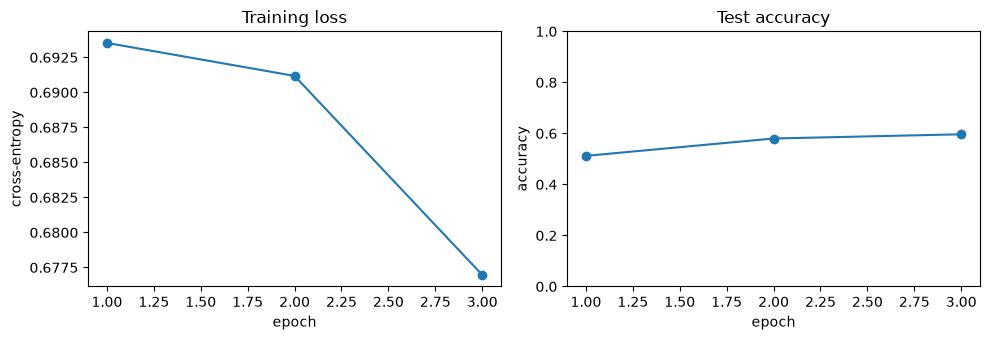

In [6]:
class BinaryCatDogDataset(Dataset):
    """CIFAR-10 cats and dogs with cat=0 and dog=1."""

    def __init__(self, dataset: datasets.CIFAR10, transform: Callable) -> None:
        self.dataset = dataset
        self.transform = transform
        self.indices = [
            index
            for index, target in enumerate(dataset.targets)
            if target in (CAT_LABEL, DOG_LABEL)
        ]

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, item: int) -> tuple[Tensor, int]:
        image, cifar_label = self.dataset[self.indices[item]]
        binary_label = int(cifar_label == DOG_LABEL)
        return self.transform(image), binary_label


base_train_set = datasets.CIFAR10(
    root=cfg.data_root,
    train=True,
    download=False,  # use the already-extracted local dataset only
    transform=None,
)
train_set = BinaryCatDogDataset(base_train_set, MODEL_TRANSFORM)
test_set = BinaryCatDogDataset(base_test_set, MODEL_TRANSFORM)

train_loader = DataLoader(
    train_set,
    batch_size=cfg.train_batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=inference_device.type == "cuda",
    generator=torch.Generator().manual_seed(cfg.seed),
)
test_loader = DataLoader(
    test_set,
    batch_size=cfg.train_batch_size,
    shuffle=False,
    num_workers=0,
    pin_memory=inference_device.type == "cuda",
)


@torch.inference_mode()
def classification_accuracy(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
) -> float:
    model.eval()
    correct = 0
    total = 0
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        predictions = model(images).argmax(dim=1)
        correct += int((predictions == labels).sum())
        total += labels.numel()
    return correct / total


model.to(inference_device)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=cfg.learning_rate,
    weight_decay=cfg.weight_decay,
)
training_loss: list[float] = []
test_accuracy: list[float] = []

for epoch in range(cfg.epochs):
    model.train()
    loss_sum = 0.0
    example_count = 0

    for images, labels in train_loader:
        images = images.to(inference_device, non_blocking=True)
        labels = labels.to(inference_device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = F.cross_entropy(logits, labels)
        loss.backward()
        optimizer.step()

        loss_sum += float(loss.detach()) * labels.numel()
        example_count += labels.numel()

    epoch_loss = loss_sum / example_count
    epoch_accuracy = classification_accuracy(model, test_loader, inference_device)
    training_loss.append(epoch_loss)
    test_accuracy.append(epoch_accuracy)
    print(
        f"Epoch {epoch + 1}/{cfg.epochs}: "
        f"loss={epoch_loss:.4f}, test_accuracy={epoch_accuracy:.3%}"
    )

history_figure, history_axes = plt.subplots(1, 2, figsize=(10, 3.5))
history_axes[0].plot(range(1, cfg.epochs + 1), training_loss, marker="o")
history_axes[0].set(title="Training loss", xlabel="epoch", ylabel="cross-entropy")
history_axes[1].plot(range(1, cfg.epochs + 1), test_accuracy, marker="o")
history_axes[1].set(title="Test accuracy", xlabel="epoch", ylabel="accuracy", ylim=(0, 1))
history_figure.tight_layout()
plt.show()

In [7]:
if model is None:
    raise RuntimeError(
        "Assign the fine-tuned model to `model` before running feature extraction."
    )

cat_features, cat_dataset_indices = collect_features(
    model, cat_loader, cls_feature_fn, inference_device
)
dog_features, dog_dataset_indices = collect_features(
    model, dog_loader, cls_feature_fn, inference_device
)

print(f"Cat feature matrix: {tuple(cat_features.shape)}")
print(f"Dog feature matrix: {tuple(dog_features.shape)}")

Cat feature matrix: (256, 192)
Dog feature matrix: (256, 192)


In [8]:
@dataclass
class SinkhornResult:
    plan: Tensor
    cost_matrix: Tensor
    transport_cost: Tensor
    regularized_objective: Tensor
    row_marginal_error: Tensor
    column_marginal_error: Tensor


def sinkhorn(
    source_features: Tensor,
    target_features: Tensor,
    epsilon: float = 0.05,
    iterations: int = 300,
) -> SinkhornResult:
    """Compute balanced entropic OT with uniform empirical weights.

    Features are normalized again defensively, and all OT calculations run in
    float32 on CPU so that the result is independent of the inference device.
    """
    if epsilon <= 0:
        raise ValueError("epsilon must be positive")

    source = F.normalize(source_features.float().cpu(), p=2, dim=1)
    target = F.normalize(target_features.float().cpu(), p=2, dim=1)
    n, m = source.shape[0], target.shape[0]

    cost = (1.0 - source @ target.T).clamp_min(0.0)
    log_a = torch.full((n,), -math.log(n), dtype=source.dtype)
    log_b = torch.full((m,), -math.log(m), dtype=target.dtype)
    log_kernel = -cost / epsilon

    log_u = torch.zeros_like(log_a)
    log_v = torch.zeros_like(log_b)

    for _ in range(iterations):
        log_u = log_a - torch.logsumexp(
            log_kernel + log_v.unsqueeze(0), dim=1
        )
        log_v = log_b - torch.logsumexp(
            log_kernel.T + log_u.unsqueeze(0), dim=1
        )

    log_plan = log_u[:, None] + log_kernel + log_v[None, :]
    plan = torch.exp(log_plan)

    transport_cost = torch.sum(plan * cost)
    regularizer = epsilon * torch.sum(plan * (log_plan - 1.0))
    regularized_objective = transport_cost + regularizer

    a = torch.exp(log_a)
    b = torch.exp(log_b)
    row_error = torch.max(torch.abs(plan.sum(dim=1) - a))
    column_error = torch.max(torch.abs(plan.sum(dim=0) - b))

    return SinkhornResult(
        plan=plan,
        cost_matrix=cost,
        transport_cost=transport_cost,
        regularized_objective=regularized_objective,
        row_marginal_error=row_error,
        column_marginal_error=column_error,
    )


def barycentric_maps(
    plan: Tensor,
    source_features: Tensor,
    target_features: Tensor,
) -> tuple[Tensor, Tensor]:
    """Return source-to-target and target-to-source feature-space maps."""
    source = F.normalize(source_features.float().cpu(), p=2, dim=1)
    target = F.normalize(target_features.float().cpu(), p=2, dim=1)

    source_to_target = (plan @ target) / plan.sum(dim=1, keepdim=True).clamp_min(1e-12)
    target_to_source = (plan.T @ source) / plan.sum(dim=0, keepdim=True).T.clamp_min(1e-12)

    return source_to_target, target_to_source


def sinkhorn_divergence(
    source_features: Tensor,
    target_features: Tensor,
    epsilon: float,
    iterations: int,
) -> tuple[Tensor, SinkhornResult]:
    cross = sinkhorn(source_features, target_features, epsilon, iterations)
    source_self = sinkhorn(source_features, source_features, epsilon, iterations)
    target_self = sinkhorn(target_features, target_features, epsilon, iterations)

    divergence = (
        cross.regularized_objective
        - 0.5 * source_self.regularized_objective
        - 0.5 * target_self.regularized_objective
    )
    return divergence, cross

In [9]:
cat_dog_divergence, cat_dog_ot = sinkhorn_divergence(
    cat_features,
    dog_features,
    epsilon=cfg.epsilon,
    iterations=cfg.sinkhorn_iterations,
)

cat_to_dog_features, dog_to_cat_features = barycentric_maps(
    cat_dog_ot.plan,
    cat_features,
    dog_features,
)

print(f"Transport cost:       {cat_dog_ot.transport_cost.item():.6f}")
print(f"Sinkhorn divergence:  {cat_dog_divergence.item():.6f}")
print(f"Maximum row error:    {cat_dog_ot.row_marginal_error.item():.3e}")
print(f"Maximum column error: {cat_dog_ot.column_marginal_error.item():.3e}")
print(f"Cat → dog map shape:  {tuple(cat_to_dog_features.shape)}")
print(f"Dog → cat map shape:  {tuple(dog_to_cat_features.shape)}")

Transport cost:       0.004522
Sinkhorn divergence:  0.000836
Maximum row error:    2.794e-09
Maximum column error: 2.328e-09
Cat → dog map shape:  (256, 192)
Dog → cat map shape:  (256, 192)


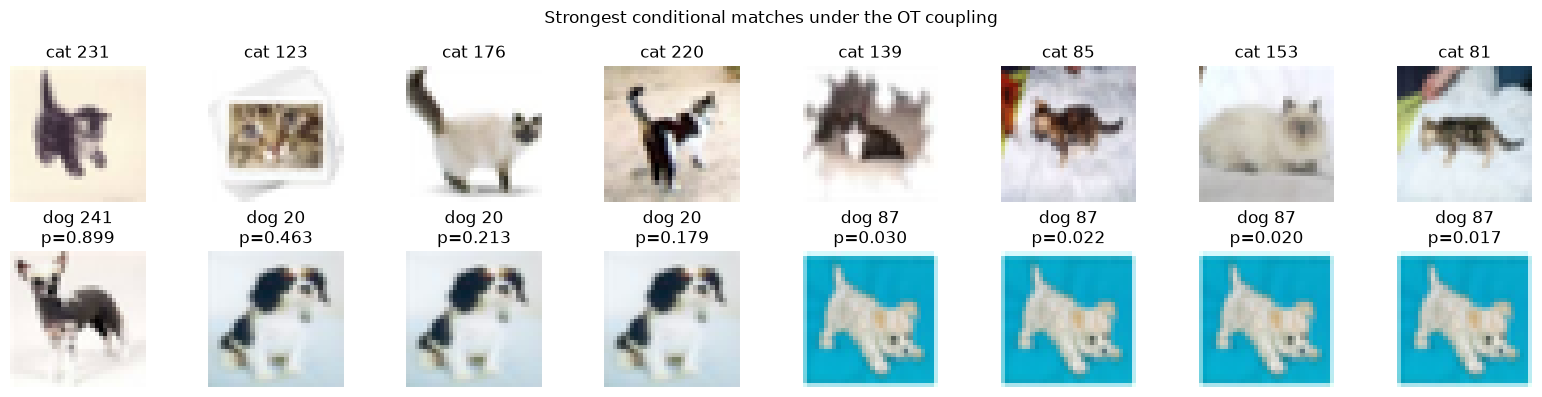

In [10]:
def show_strongest_matches(
    plan: Tensor,
    cat_indices: Tensor,
    dog_indices: Tensor,
    raw_dataset: datasets.CIFAR10,
    number_of_pairs: int = 8,
) -> None:
    """Display high-confidence cat-to-dog matches from the OT coupling."""
    conditional_plan = plan / plan.sum(dim=1, keepdim=True).clamp_min(1e-12)
    best_dog_for_cat = conditional_plan.argmax(dim=1)
    match_probability = conditional_plan.max(dim=1).values

    k = min(number_of_pairs, plan.shape[0])
    selected_cats = torch.topk(match_probability, k=k).indices

    figure, axes = plt.subplots(2, k, figsize=(2 * k, 4))
    if k == 1:
        axes = axes.reshape(2, 1)

    for column, cat_position in enumerate(selected_cats.tolist()):
        dog_position = int(best_dog_for_cat[cat_position])
        cat_image, _ = raw_dataset[int(cat_indices[cat_position])]
        dog_image, _ = raw_dataset[int(dog_indices[dog_position])]

        axes[0, column].imshow(cat_image)
        axes[0, column].set_title(f"cat {cat_position}")
        axes[0, column].axis("off")

        axes[1, column].imshow(dog_image)
        axes[1, column].set_title(
            f"dog {dog_position}\np={match_probability[cat_position]:.3f}"
        )
        axes[1, column].axis("off")

    figure.suptitle("Strongest conditional matches under the OT coupling")
    figure.tight_layout()
    plt.show()


show_strongest_matches(
    cat_dog_ot.plan,
    cat_dataset_indices,
    dog_dataset_indices,
    base_test_set,
)

## Displacement interpolation from $P_c$ to $P_d$

The OT plan defines a barycentric target $T_{c\rightarrow d}(z_i^c)$ for each cat feature. At time $t\in[0,1]$, its displacement interpolation is

$$
z_i(t)=(1-t)z_i^c+tT_{c\rightarrow d}(z_i^c).
$$

The animation below projects these feature-space trajectories to two principal components. It visualizes the empirical cat distribution moving toward its OT barycenters in the dog distribution; it is not an image-generation process.

The second visualization follows one trajectory using its nearest observed CIFAR-10 image at each time. Those images are representatives from the dataset, not decoded intermediate frames.

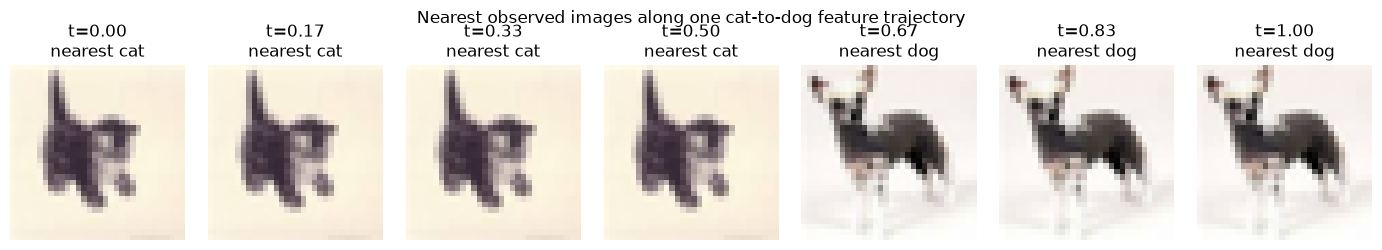

In [11]:
from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation


def fit_pca_2d(*feature_sets: Tensor) -> tuple[Tensor, Tensor]:
    combined = torch.cat([features.float().cpu() for features in feature_sets])
    center = combined.mean(dim=0, keepdim=True)
    _, _, right_vectors = torch.linalg.svd(combined - center, full_matrices=False)
    components = right_vectors[:2].T
    return center, components


def project_2d(features: Tensor, center: Tensor, components: Tensor) -> Tensor:
    return (features.float().cpu() - center) @ components


pca_center, pca_components = fit_pca_2d(
    cat_features,
    dog_features,
    cat_to_dog_features,
)

number_of_frames = 31
particle_count = min(64, len(cat_features))
frame_times = torch.linspace(0.0, 1.0, number_of_frames)
particle_indices = torch.linspace(
    0, len(cat_features) - 1, particle_count
).round().long()

cat_particles = cat_features[particle_indices]
dog_barycenters = cat_to_dog_features[particle_indices]
feature_trajectories = torch.stack(
    [
        (1.0 - time) * cat_particles + time * dog_barycenters
        for time in frame_times
    ]
)
projected_trajectories = torch.stack(
    [project_2d(frame, pca_center, pca_components) for frame in feature_trajectories]
)
projected_dogs = project_2d(dog_features, pca_center, pca_components)

all_projected = torch.cat(
    [projected_trajectories.reshape(-1, 2), projected_dogs], dim=0
)
padding = 0.05 * (all_projected.max(dim=0).values - all_projected.min(dim=0).values)
plot_min = all_projected.min(dim=0).values - padding
plot_max = all_projected.max(dim=0).values + padding

figure, axis = plt.subplots(figsize=(7, 6))
axis.scatter(
    projected_dogs[:, 0],
    projected_dogs[:, 1],
    s=14,
    alpha=0.25,
    color="tab:blue",
    label="$P_d$ dog features",
)
for particle in range(particle_count):
    path = projected_trajectories[:, particle]
    axis.plot(path[:, 0], path[:, 1], color="0.75", linewidth=0.5, alpha=0.4)

moving_scatter = axis.scatter([], [], s=30, color="tab:orange", label="transported $P_c$")
axis.set(
    xlim=(float(plot_min[0]), float(plot_max[0])),
    ylim=(float(plot_min[1]), float(plot_max[1])),
    xlabel="PC 1",
    ylabel="PC 2",
)
axis.legend(loc="best")


def update_transport_frame(frame: int):
    points = projected_trajectories[frame]
    moving_scatter.set_offsets(points.numpy())
    moving_scatter.set_color(plt.cm.coolwarm(float(frame_times[frame])))
    axis.set_title(f"Cat → dog displacement interpolation, t={frame_times[frame]:.2f}")
    return (moving_scatter,)


transport_animation = FuncAnimation(
    figure,
    update_transport_frame,
    frames=number_of_frames,
    interval=120,
    blit=False,
)
display(HTML(transport_animation.to_jshtml()))
plt.close(figure)


# Follow one feature trajectory with nearest observed images. These are dataset
# representatives, not images synthesized by the transport map.
conditional_plan = cat_dog_ot.plan / cat_dog_ot.plan.sum(
    dim=1, keepdim=True
).clamp_min(1e-12)
source_cat = int(conditional_plan.max(dim=1).values.argmax())
source_feature = cat_features[source_cat]
target_feature = cat_to_dog_features[source_cat]
representative_times = torch.linspace(0.0, 1.0, 7)
representative_trajectory = torch.stack(
    [
        F.normalize(
            ((1.0 - time) * source_feature + time * target_feature).unsqueeze(0),
            dim=1,
        ).squeeze(0)
        for time in representative_times
    ]
)

reference_features = F.normalize(
    torch.cat([cat_features, dog_features]), p=2, dim=1
)
nearest_references = (representative_trajectory @ reference_features.T).argmax(dim=1)

representative_figure, representative_axes = plt.subplots(
    1, len(representative_times), figsize=(14, 2.5)
)
for axis_item, time, reference_position in zip(
    representative_axes,
    representative_times,
    nearest_references,
):
    position = int(reference_position)
    if position < len(cat_features):
        class_name = "cat"
        dataset_index = int(cat_dataset_indices[position])
    else:
        class_name = "dog"
        dog_position = position - len(cat_features)
        dataset_index = int(dog_dataset_indices[dog_position])

    image, _ = base_test_set[dataset_index]
    axis_item.imshow(image)
    axis_item.set_title(f"t={time:.2f}\nnearest {class_name}")
    axis_item.axis("off")

representative_figure.suptitle(
    "Nearest observed images along one cat-to-dog feature trajectory"
)
representative_figure.tight_layout()
plt.show()

Epoch 01/20: train_loss=0.6923, test_loss=0.6899, test_accuracy=55.50%
Epoch 02/20: train_loss=0.6899, test_loss=0.6887, test_accuracy=53.25%
Epoch 03/20: train_loss=0.6901, test_loss=0.6834, test_accuracy=56.45%
Epoch 04/20: train_loss=0.6867, test_loss=0.6815, test_accuracy=55.70%
Epoch 05/20: train_loss=0.6874, test_loss=0.6836, test_accuracy=55.00%
Epoch 06/20: train_loss=0.6848, test_loss=0.6734, test_accuracy=58.80%
Epoch 07/20: train_loss=0.6772, test_loss=0.6702, test_accuracy=58.45%
Epoch 08/20: train_loss=0.6727, test_loss=0.6691, test_accuracy=59.15%
Epoch 09/20: train_loss=0.6710, test_loss=0.6543, test_accuracy=61.55%
Epoch 10/20: train_loss=0.6648, test_loss=0.6504, test_accuracy=62.75%
Epoch 11/20: train_loss=0.6588, test_loss=0.6504, test_accuracy=62.25%
Epoch 12/20: train_loss=0.6522, test_loss=0.6394, test_accuracy=62.20%
Epoch 13/20: train_loss=0.6467, test_loss=0.6337, test_accuracy=64.70%
Epoch 14/20: train_loss=0.6364, test_loss=0.6305, test_accuracy=64.05%
Epoch 

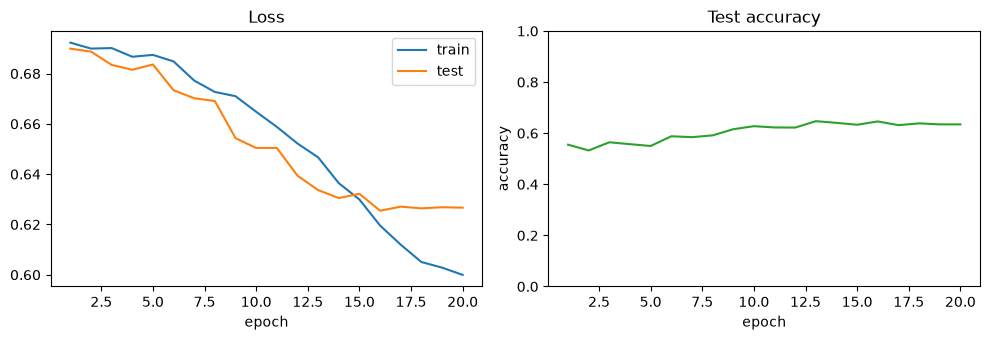

20-epoch transport cost: 0.119046
20-epoch Sinkhorn divergence: 0.054740


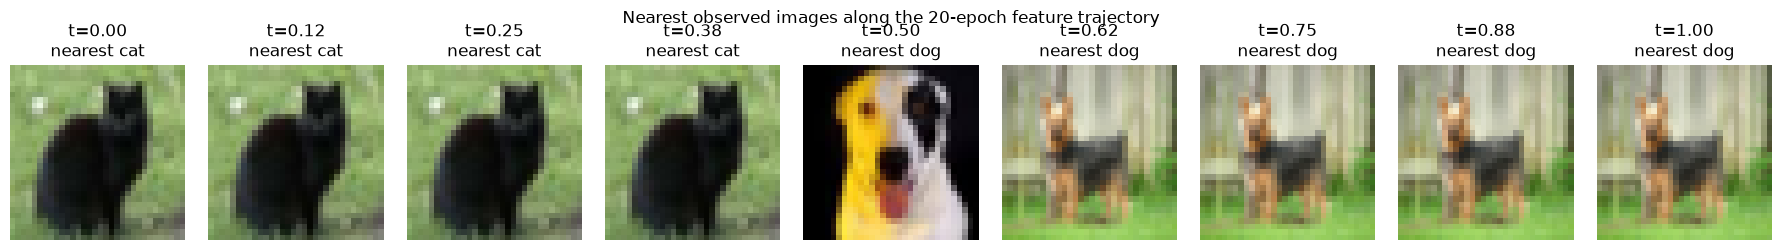

In [12]:
# Improved 20-epoch CIFAR-10 experiment with standard normalization.
# This cell is intentionally separate from the short smoke test above.
from copy import deepcopy

from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation

STANDARD_EPOCHS = 20
STANDARD_IMAGE_SIZE = 64  # four 16x16 patches per side
STANDARD_BATCH_SIZE = 256
STANDARD_LEARNING_RATE = 5e-4
STANDARD_WEIGHT_DECAY = 0.05

# Keep dataset loading cheap. Resizing, augmentation, and normalization are
# applied to whole batches on MPS by standard_prepare_batch below.
standard_train_transform = transforms.ToTensor()
standard_eval_transform = transforms.ToTensor()
standard_mean = torch.tensor(
    (0.485, 0.456, 0.406), device=inference_device
).view(1, 3, 1, 1)
standard_std = torch.tensor(
    (0.229, 0.224, 0.225), device=inference_device
).view(1, 3, 1, 1)


def standard_prepare_batch(images: Tensor, training: bool) -> Tensor:
    images = images.to(inference_device, non_blocking=True)
    if training:
        flip_mask = torch.rand(images.shape[0], device=inference_device) < 0.5
        images[flip_mask] = torch.flip(images[flip_mask], dims=(3,))
    images = F.interpolate(
        images,
        size=(STANDARD_IMAGE_SIZE, STANDARD_IMAGE_SIZE),
        mode="bilinear",
        align_corners=False,
    )
    return (images - standard_mean) / standard_std


class StandardBinaryCatDogDataset(Dataset):
    def __init__(self, dataset: datasets.CIFAR10, transform: Callable) -> None:
        self.dataset = dataset
        self.transform = transform
        self.indices = [
            index
            for index, target in enumerate(dataset.targets)
            if target in (CAT_LABEL, DOG_LABEL)
        ]

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, item: int) -> tuple[Tensor, int]:
        image, cifar_label = self.dataset[self.indices[item]]
        label = int(cifar_label == DOG_LABEL)
        return self.transform(image), label


standard_base_train = datasets.CIFAR10(
    root=cfg.data_root,
    train=True,
    download=False,  # use the already-extracted local dataset only
    transform=None,
)
standard_train_set = StandardBinaryCatDogDataset(
    standard_base_train, standard_train_transform
)
standard_test_set = StandardBinaryCatDogDataset(
    base_test_set, standard_eval_transform
)
standard_train_loader = DataLoader(
    standard_train_set,
    batch_size=STANDARD_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(cfg.seed),
)
standard_test_loader = DataLoader(
    standard_test_set,
    batch_size=STANDARD_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

# Reinitialize so this experiment does not continue from the three-epoch model.
torch.manual_seed(cfg.seed)
standard_model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=2,
    img_size=STANDARD_IMAGE_SIZE,
).to(inference_device)
standard_optimizer = torch.optim.AdamW(
    standard_model.parameters(),
    lr=STANDARD_LEARNING_RATE,
    weight_decay=STANDARD_WEIGHT_DECAY,
)
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    standard_optimizer, start_factor=0.1, total_iters=2
)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    standard_optimizer, T_max=STANDARD_EPOCHS - 2
)
standard_scheduler = torch.optim.lr_scheduler.SequentialLR(
    standard_optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[2],
)


@torch.inference_mode()
def evaluate_standard_model(model: nn.Module) -> tuple[float, float]:
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    for images, labels in standard_test_loader:
        images = standard_prepare_batch(images, training=False)
        labels = labels.to(inference_device, non_blocking=True)
        logits = model(images)
        loss_sum += float(F.cross_entropy(logits, labels)) * labels.numel()
        correct += int((logits.argmax(dim=1) == labels).sum())
        total += labels.numel()
    return loss_sum / total, correct / total


standard_history = {"train_loss": [], "test_loss": [], "test_accuracy": []}
best_accuracy = -1.0
best_state: dict[str, Tensor] | None = None

for epoch in range(STANDARD_EPOCHS):
    standard_model.train()
    running_loss = 0.0
    example_count = 0

    for images, labels in standard_train_loader:
        images = standard_prepare_batch(images, training=True)
        labels = labels.to(inference_device, non_blocking=True)

        standard_optimizer.zero_grad(set_to_none=True)
        logits = standard_model(images)
        loss = F.cross_entropy(logits, labels, label_smoothing=0.1)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(standard_model.parameters(), max_norm=1.0)
        standard_optimizer.step()

        running_loss += float(loss.detach()) * labels.numel()
        example_count += labels.numel()

    train_loss = running_loss / example_count
    test_loss, accuracy = evaluate_standard_model(standard_model)
    standard_scheduler.step()

    standard_history["train_loss"].append(train_loss)
    standard_history["test_loss"].append(test_loss)
    standard_history["test_accuracy"].append(accuracy)

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_state = deepcopy(standard_model.state_dict())

    print(
        f"Epoch {epoch + 1:02d}/{STANDARD_EPOCHS}: "
        f"train_loss={train_loss:.4f}, test_loss={test_loss:.4f}, "
        f"test_accuracy={accuracy:.2%}"
    )

assert best_state is not None
standard_model.load_state_dict(best_state)
print(f"Best test accuracy: {best_accuracy:.2%}")

standard_history_figure, standard_history_axes = plt.subplots(1, 2, figsize=(10, 3.5))
epoch_axis = range(1, STANDARD_EPOCHS + 1)
standard_history_axes[0].plot(
    epoch_axis, standard_history["train_loss"], label="train"
)
standard_history_axes[0].plot(
    epoch_axis, standard_history["test_loss"], label="test"
)
standard_history_axes[0].set(title="Loss", xlabel="epoch")
standard_history_axes[0].legend()
standard_history_axes[1].plot(
    epoch_axis, standard_history["test_accuracy"], color="tab:green"
)
standard_history_axes[1].set(
    title="Test accuracy", xlabel="epoch", ylabel="accuracy", ylim=(0, 1)
)
standard_history_figure.tight_layout()
plt.show()

# Extract balanced test features using the standard evaluation transform.
standard_cat_set = CIFARClassSubset(
    base_test_set, CAT_LABEL, standard_eval_transform, cfg.samples_per_class
)
standard_dog_set = CIFARClassSubset(
    base_test_set, DOG_LABEL, standard_eval_transform, cfg.samples_per_class
)
standard_cat_loader = DataLoader(
    standard_cat_set, batch_size=cfg.batch_size, shuffle=False, num_workers=0
)
standard_dog_loader = DataLoader(
    standard_dog_set, batch_size=cfg.batch_size, shuffle=False, num_workers=0
)


@torch.inference_mode()
def collect_standard_features(loader: DataLoader) -> tuple[Tensor, Tensor]:
    standard_model.eval()
    feature_batches: list[Tensor] = []
    index_batches: list[Tensor] = []
    for images, dataset_indices in loader:
        images = standard_prepare_batch(images, training=False)
        features = cls_feature_fn(standard_model, images)
        feature_batches.append(F.normalize(features.float(), p=2, dim=1).cpu())
        index_batches.append(dataset_indices.cpu())
    return torch.cat(feature_batches), torch.cat(index_batches)


standard_cat_features, standard_cat_indices = collect_standard_features(
    standard_cat_loader
)
standard_dog_features, standard_dog_indices = collect_standard_features(
    standard_dog_loader
)
standard_divergence, standard_ot = sinkhorn_divergence(
    standard_cat_features,
    standard_dog_features,
    epsilon=cfg.epsilon,
    iterations=cfg.sinkhorn_iterations,
)
standard_cat_to_dog, _ = barycentric_maps(
    standard_ot.plan, standard_cat_features, standard_dog_features
)
print(f"20-epoch transport cost: {standard_ot.transport_cost.item():.6f}")
print(f"20-epoch Sinkhorn divergence: {standard_divergence.item():.6f}")

# Inline displacement animation in a two-dimensional PCA projection.
standard_pca_data = torch.cat(
    [standard_cat_features, standard_dog_features, standard_cat_to_dog]
).float()
standard_pca_center = standard_pca_data.mean(dim=0, keepdim=True)
_, _, standard_right_vectors = torch.linalg.svd(
    standard_pca_data - standard_pca_center, full_matrices=False
)
standard_pca_components = standard_right_vectors[:2].T


def standard_project(features: Tensor) -> Tensor:
    return (features.float().cpu() - standard_pca_center) @ standard_pca_components


standard_frame_times = torch.linspace(0.0, 1.0, 41)
standard_particle_indices = torch.linspace(
    0, len(standard_cat_features) - 1, 96
).round().long()
standard_sources = standard_cat_features[standard_particle_indices]
standard_targets = standard_cat_to_dog[standard_particle_indices]
standard_trajectories = torch.stack(
    [
        standard_project((1.0 - time) * standard_sources + time * standard_targets)
        for time in standard_frame_times
    ]
)
standard_projected_dogs = standard_project(standard_dog_features)
standard_plot_data = torch.cat(
    [standard_trajectories.reshape(-1, 2), standard_projected_dogs]
)
standard_plot_padding = 0.05 * (
    standard_plot_data.max(dim=0).values - standard_plot_data.min(dim=0).values
)
standard_plot_min = standard_plot_data.min(dim=0).values - standard_plot_padding
standard_plot_max = standard_plot_data.max(dim=0).values + standard_plot_padding

standard_animation_figure, standard_animation_axis = plt.subplots(figsize=(7, 6))
standard_animation_axis.scatter(
    standard_projected_dogs[:, 0],
    standard_projected_dogs[:, 1],
    s=16,
    alpha=0.25,
    color="tab:blue",
    label="$P_d$ dog features",
)
for particle in range(standard_trajectories.shape[1]):
    path = standard_trajectories[:, particle]
    standard_animation_axis.plot(
        path[:, 0], path[:, 1], color="0.75", linewidth=0.5, alpha=0.35
    )
standard_moving_scatter = standard_animation_axis.scatter(
    [], [], s=30, color="tab:orange", label="transported $P_c$"
)
standard_animation_axis.set(
    xlim=(float(standard_plot_min[0]), float(standard_plot_max[0])),
    ylim=(float(standard_plot_min[1]), float(standard_plot_max[1])),
    xlabel="PC 1",
    ylabel="PC 2",
)
standard_animation_axis.legend(loc="best")


def update_standard_transport(frame: int):
    points = standard_trajectories[frame]
    standard_moving_scatter.set_offsets(points.numpy())
    standard_moving_scatter.set_color(
        plt.cm.coolwarm(float(standard_frame_times[frame]))
    )
    standard_animation_axis.set_title(
        f"20-epoch cat → dog transport, t={standard_frame_times[frame]:.2f}"
    )
    return (standard_moving_scatter,)


standard_transport_animation = FuncAnimation(
    standard_animation_figure,
    update_standard_transport,
    frames=len(standard_frame_times),
    interval=120,
    blit=False,
)
display(HTML(standard_transport_animation.to_jshtml()))
plt.close(standard_animation_figure)

# Nearest observed images along a high-confidence feature trajectory.
standard_conditional_plan = standard_ot.plan / standard_ot.plan.sum(
    dim=1, keepdim=True
).clamp_min(1e-12)
standard_source_cat = int(standard_conditional_plan.max(dim=1).values.argmax())
standard_source = standard_cat_features[standard_source_cat]
standard_target = standard_cat_to_dog[standard_source_cat]
standard_representative_times = torch.linspace(0.0, 1.0, 9)
standard_representative_features = torch.stack(
    [
        F.normalize(
            ((1.0 - time) * standard_source + time * standard_target).unsqueeze(0),
            dim=1,
        ).squeeze(0)
        for time in standard_representative_times
    ]
)
standard_reference_bank = F.normalize(
    torch.cat([standard_cat_features, standard_dog_features]), p=2, dim=1
)
standard_nearest = (
    standard_representative_features @ standard_reference_bank.T
).argmax(dim=1)

standard_representative_figure, standard_representative_axes = plt.subplots(
    1, len(standard_representative_times), figsize=(18, 2.5)
)
for axis_item, time, reference_position in zip(
    standard_representative_axes,
    standard_representative_times,
    standard_nearest,
):
    position = int(reference_position)
    if position < len(standard_cat_features):
        class_name = "cat"
        dataset_index = int(standard_cat_indices[position])
    else:
        class_name = "dog"
        dog_position = position - len(standard_cat_features)
        dataset_index = int(standard_dog_indices[dog_position])
    image, _ = base_test_set[dataset_index]
    axis_item.imshow(image)
    axis_item.set_title(f"t={time:.2f}\nnearest {class_name}")
    axis_item.axis("off")
standard_representative_figure.suptitle(
    "Nearest observed images along the 20-epoch feature trajectory"
)
standard_representative_figure.tight_layout()
plt.show()

## Improved classifier: consistency KL, gated token fusion, and CIFAR normalization

This experiment is an alternative to the preceding baseline. It keeps the randomly initialized smallest DINOv3 backbone but changes three aspects:

1. **Better normalization:** use CIFAR-10 channel statistics rather than ImageNet statistics.
2. **Gated representation:** learn a feature-wise gate between the normalized CLS token and the mean normalized patch token.
3. **Consistency KL:** classify two independently augmented views of each image and penalize their symmetric KL divergence.

The KL term is applied between predictions of two views of the same image. It is not applied between $P_c$ and $P_d$, because directly forcing those class distributions together would weaken class separation.

In [ ]:
# Run this cell instead of the preceding baseline experiment when comparing
# the gated/consistency-regularized model.
from copy import deepcopy

from IPython.display import HTML, display
from matplotlib.animation import FuncAnimation

IMPROVED_EPOCHS = 30
IMPROVED_IMAGE_SIZE = 64  # 4x4 patch grid with 16-pixel patches
IMPROVED_BATCH_SIZE = 256
IMPROVED_LEARNING_RATE = 5e-4
IMPROVED_WEIGHT_DECAY = 0.05
CONSISTENCY_KL_WEIGHT = 0.25
GATE_BALANCE_WEIGHT = 0.01

cifar_mean = torch.tensor(
    (0.4914, 0.4822, 0.4465), device=inference_device
).view(1, 3, 1, 1)
cifar_std = torch.tensor(
    (0.2470, 0.2435, 0.2616), device=inference_device
).view(1, 3, 1, 1)
raw_tensor_transform = transforms.ToTensor()


class ImprovedBinaryCatDogDataset(Dataset):
    def __init__(self, dataset: datasets.CIFAR10) -> None:
        self.dataset = dataset
        self.indices = [
            index
            for index, target in enumerate(dataset.targets)
            if target in (CAT_LABEL, DOG_LABEL)
        ]

    def __len__(self) -> int:
        return len(self.indices)

    def __getitem__(self, item: int) -> tuple[Tensor, int]:
        image, cifar_label = self.dataset[self.indices[item]]
        return raw_tensor_transform(image), int(cifar_label == DOG_LABEL)


improved_base_train = datasets.CIFAR10(
    root=cfg.data_root,
    train=True,
    download=False,
    transform=None,
)
improved_train_set = ImprovedBinaryCatDogDataset(improved_base_train)
improved_test_set = ImprovedBinaryCatDogDataset(base_test_set)
improved_train_loader = DataLoader(
    improved_train_set,
    batch_size=IMPROVED_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(cfg.seed),
)
improved_test_loader = DataLoader(
    improved_test_set,
    batch_size=IMPROVED_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)


def prepare_improved_batch(images: Tensor, training: bool) -> Tensor:
    """Apply fast batch augmentation, resize, and CIFAR normalization on MPS."""
    images = images.to(inference_device, non_blocking=True)
    if training:
        flip_mask = torch.rand(images.shape[0], device=inference_device) < 0.5
        images[flip_mask] = torch.flip(images[flip_mask], dims=(3,))

        brightness = 1.0 + 0.2 * (
            2.0 * torch.rand(images.shape[0], 1, 1, 1, device=inference_device) - 1.0
        )
        contrast = 1.0 + 0.2 * (
            2.0 * torch.rand(images.shape[0], 1, 1, 1, device=inference_device) - 1.0
        )
        image_means = images.mean(dim=(2, 3), keepdim=True)
        images = (images - image_means) * contrast + image_means
        images = (images * brightness).clamp(0.0, 1.0)

    images = F.interpolate(
        images,
        size=(IMPROVED_IMAGE_SIZE, IMPROVED_IMAGE_SIZE),
        mode="bilinear",
        align_corners=False,
    )
    return (images - cifar_mean) / cifar_std


class GatedDinoClassifier(nn.Module):
    """Fuse CLS and patch summaries with a learned feature-wise gate."""

    def __init__(self) -> None:
        super().__init__()
        self.backbone = timm.create_model(
            MODEL_NAME,
            pretrained=False,
            num_classes=0,
            img_size=IMPROVED_IMAGE_SIZE,
        )
        feature_dim = self.backbone.num_features
        self.cls_norm = nn.LayerNorm(feature_dim)
        self.patch_norm = nn.LayerNorm(feature_dim)
        self.gate = nn.Sequential(
            nn.Linear(2 * feature_dim, feature_dim),
            nn.Sigmoid(),
        )
        self.fusion_norm = nn.LayerNorm(feature_dim)
        self.classifier = nn.Sequential(
            nn.Dropout(0.15),
            nn.Linear(feature_dim, 2),
        )

    def encode_with_gate(self, images: Tensor) -> tuple[Tensor, Tensor]:
        tokens = self.backbone.forward_features(images)
        if not isinstance(tokens, Tensor) or tokens.ndim != 3:
            raise ValueError("Expected DINO features with shape [B, tokens, D]")

        prefix_tokens = int(getattr(self.backbone, "num_prefix_tokens", 1))
        cls_feature = self.cls_norm(tokens[:, 0])
        patch_feature = self.patch_norm(tokens[:, prefix_tokens:].mean(dim=1))
        gate = self.gate(torch.cat([cls_feature, patch_feature], dim=1))
        fused_feature = self.fusion_norm(
            gate * cls_feature + (1.0 - gate) * patch_feature
        )
        return fused_feature, gate

    def forward_features(self, images: Tensor) -> Tensor:
        features, _ = self.encode_with_gate(images)
        return features

    def forward(
        self, images: Tensor, return_gate: bool = False
    ) -> Tensor | tuple[Tensor, Tensor]:
        features, gate = self.encode_with_gate(images)
        logits = self.classifier(features)
        if return_gate:
            return logits, gate
        return logits


def symmetric_prediction_kl(logits_a: Tensor, logits_b: Tensor) -> Tensor:
    log_a = F.log_softmax(logits_a, dim=1)
    log_b = F.log_softmax(logits_b, dim=1)
    probability_a = log_a.exp()
    probability_b = log_b.exp()
    kl_a_b = torch.sum(probability_a * (log_a - log_b), dim=1).mean()
    kl_b_a = torch.sum(probability_b * (log_b - log_a), dim=1).mean()
    return 0.5 * (kl_a_b + kl_b_a)


torch.manual_seed(cfg.seed)
improved_model = GatedDinoClassifier().to(inference_device)
improved_optimizer = torch.optim.AdamW(
    improved_model.parameters(),
    lr=IMPROVED_LEARNING_RATE,
    weight_decay=IMPROVED_WEIGHT_DECAY,
)
improved_warmup = torch.optim.lr_scheduler.LinearLR(
    improved_optimizer, start_factor=0.1, total_iters=3
)
improved_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(
    improved_optimizer, T_max=IMPROVED_EPOCHS - 3
)
improved_scheduler = torch.optim.lr_scheduler.SequentialLR(
    improved_optimizer,
    schedulers=[improved_warmup, improved_cosine],
    milestones=[3],
)


@torch.inference_mode()
def evaluate_improved_model() -> tuple[float, float, float]:
    improved_model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0
    gate_sum = 0.0
    gate_elements = 0

    for images, labels in improved_test_loader:
        images = prepare_improved_batch(images, training=False)
        labels = labels.to(inference_device, non_blocking=True)
        logits, gate = improved_model(images, return_gate=True)
        loss_sum += float(F.cross_entropy(logits, labels)) * labels.numel()
        correct += int((logits.argmax(dim=1) == labels).sum())
        total += labels.numel()
        gate_sum += float(gate.sum())
        gate_elements += gate.numel()

    return loss_sum / total, correct / total, gate_sum / gate_elements


improved_history = {
    "train_loss": [],
    "test_loss": [],
    "test_accuracy": [],
    "gate_mean": [],
}
improved_best_accuracy = -1.0
improved_best_state: dict[str, Tensor] | None = None

for epoch in range(IMPROVED_EPOCHS):
    improved_model.train()
    running_loss = 0.0
    example_count = 0

    for raw_images, labels in improved_train_loader:
        labels = labels.to(inference_device, non_blocking=True)
        view_a = prepare_improved_batch(raw_images.clone(), training=True)
        view_b = prepare_improved_batch(raw_images.clone(), training=True)

        improved_optimizer.zero_grad(set_to_none=True)
        logits_a, gate_a = improved_model(view_a, return_gate=True)
        logits_b, gate_b = improved_model(view_b, return_gate=True)

        classification_loss = 0.5 * (
            F.cross_entropy(logits_a, labels, label_smoothing=0.1)
            + F.cross_entropy(logits_b, labels, label_smoothing=0.1)
        )
        consistency_loss = symmetric_prediction_kl(logits_a, logits_b)
        combined_gate = torch.cat([gate_a, gate_b], dim=0)
        gate_balance_loss = (combined_gate.mean(dim=0) - 0.5).square().mean()
        loss = (
            classification_loss
            + CONSISTENCY_KL_WEIGHT * consistency_loss
            + GATE_BALANCE_WEIGHT * gate_balance_loss
        )
        loss.backward()
        torch.nn.utils.clip_grad_norm_(improved_model.parameters(), max_norm=1.0)
        improved_optimizer.step()

        running_loss += float(loss.detach()) * labels.numel()
        example_count += labels.numel()

    train_loss = running_loss / example_count
    test_loss, test_accuracy, gate_mean = evaluate_improved_model()
    improved_scheduler.step()

    improved_history["train_loss"].append(train_loss)
    improved_history["test_loss"].append(test_loss)
    improved_history["test_accuracy"].append(test_accuracy)
    improved_history["gate_mean"].append(gate_mean)

    if test_accuracy > improved_best_accuracy:
        improved_best_accuracy = test_accuracy
        improved_best_state = deepcopy(improved_model.state_dict())

    print(
        f"Epoch {epoch + 1:02d}/{IMPROVED_EPOCHS}: "
        f"train_loss={train_loss:.4f}, test_loss={test_loss:.4f}, "
        f"accuracy={test_accuracy:.2%}, gate_mean={gate_mean:.3f}"
    )

assert improved_best_state is not None
improved_model.load_state_dict(improved_best_state)
print(f"Best gated-model test accuracy: {improved_best_accuracy:.2%}")

improved_history_figure, improved_history_axes = plt.subplots(1, 3, figsize=(14, 3.5))
improved_epoch_axis = range(1, IMPROVED_EPOCHS + 1)
improved_history_axes[0].plot(
    improved_epoch_axis, improved_history["train_loss"], label="train"
)
improved_history_axes[0].plot(
    improved_epoch_axis, improved_history["test_loss"], label="test"
)
improved_history_axes[0].set(title="Loss", xlabel="epoch")
improved_history_axes[0].legend()
improved_history_axes[1].plot(
    improved_epoch_axis, improved_history["test_accuracy"], color="tab:green"
)
improved_history_axes[1].set(
    title="Test accuracy", xlabel="epoch", ylabel="accuracy", ylim=(0, 1)
)
improved_history_axes[2].plot(
    improved_epoch_axis, improved_history["gate_mean"], color="tab:purple"
)
improved_history_axes[2].axhline(0.5, color="0.5", linestyle="--", linewidth=1)
improved_history_axes[2].set(
    title="Mean CLS gate", xlabel="epoch", ylabel="gate value", ylim=(0, 1)
)
improved_history_figure.tight_layout()
plt.show()

# Extract gated features and recompute OT.
improved_cat_set = CIFARClassSubset(
    base_test_set, CAT_LABEL, raw_tensor_transform, cfg.samples_per_class
)
improved_dog_set = CIFARClassSubset(
    base_test_set, DOG_LABEL, raw_tensor_transform, cfg.samples_per_class
)
improved_cat_loader = DataLoader(
    improved_cat_set, batch_size=cfg.batch_size, shuffle=False, num_workers=0
)
improved_dog_loader = DataLoader(
    improved_dog_set, batch_size=cfg.batch_size, shuffle=False, num_workers=0
)


@torch.inference_mode()
def collect_improved_features(loader: DataLoader) -> tuple[Tensor, Tensor]:
    improved_model.eval()
    feature_batches: list[Tensor] = []
    index_batches: list[Tensor] = []
    for images, dataset_indices in loader:
        images = prepare_improved_batch(images, training=False)
        features = improved_model.forward_features(images)
        feature_batches.append(F.normalize(features.float(), p=2, dim=1).cpu())
        index_batches.append(dataset_indices.cpu())
    return torch.cat(feature_batches), torch.cat(index_batches)


improved_cat_features, improved_cat_indices = collect_improved_features(
    improved_cat_loader
)
improved_dog_features, improved_dog_indices = collect_improved_features(
    improved_dog_loader
)
improved_divergence, improved_ot = sinkhorn_divergence(
    improved_cat_features,
    improved_dog_features,
    epsilon=cfg.epsilon,
    iterations=cfg.sinkhorn_iterations,
)
improved_cat_to_dog, _ = barycentric_maps(
    improved_ot.plan, improved_cat_features, improved_dog_features
)
print(f"Gated transport cost: {improved_ot.transport_cost.item():.6f}")
print(f"Gated Sinkhorn divergence: {improved_divergence.item():.6f}")

# Inline displacement interpolation for the improved representation.
improved_pca_data = torch.cat(
    [improved_cat_features, improved_dog_features, improved_cat_to_dog]
).float()
improved_pca_center = improved_pca_data.mean(dim=0, keepdim=True)
_, _, improved_right_vectors = torch.linalg.svd(
    improved_pca_data - improved_pca_center, full_matrices=False
)
improved_pca_components = improved_right_vectors[:2].T


def project_improved(features: Tensor) -> Tensor:
    return (features.float().cpu() - improved_pca_center) @ improved_pca_components


improved_times = torch.linspace(0.0, 1.0, 41)
improved_particle_indices = torch.linspace(
    0, len(improved_cat_features) - 1, 96
).round().long()
improved_sources = improved_cat_features[improved_particle_indices]
improved_targets = improved_cat_to_dog[improved_particle_indices]
improved_trajectories = torch.stack(
    [
        project_improved((1.0 - time) * improved_sources + time * improved_targets)
        for time in improved_times
    ]
)
improved_projected_dogs = project_improved(improved_dog_features)
improved_plot_data = torch.cat(
    [improved_trajectories.reshape(-1, 2), improved_projected_dogs]
)
improved_padding = 0.05 * (
    improved_plot_data.max(dim=0).values - improved_plot_data.min(dim=0).values
)
improved_plot_min = improved_plot_data.min(dim=0).values - improved_padding
improved_plot_max = improved_plot_data.max(dim=0).values + improved_padding

improved_animation_figure, improved_animation_axis = plt.subplots(figsize=(7, 6))
improved_animation_axis.scatter(
    improved_projected_dogs[:, 0],
    improved_projected_dogs[:, 1],
    s=16,
    alpha=0.25,
    color="tab:blue",
    label="$P_d$ dog features",
)
for particle in range(improved_trajectories.shape[1]):
    path = improved_trajectories[:, particle]
    improved_animation_axis.plot(
        path[:, 0], path[:, 1], color="0.75", linewidth=0.5, alpha=0.35
    )
improved_moving_scatter = improved_animation_axis.scatter(
    [], [], s=30, color="tab:orange", label="transported $P_c$"
)
improved_animation_axis.set(
    xlim=(float(improved_plot_min[0]), float(improved_plot_max[0])),
    ylim=(float(improved_plot_min[1]), float(improved_plot_max[1])),
    xlabel="PC 1",
    ylabel="PC 2",
)
improved_animation_axis.legend(loc="best")


def update_improved_transport(frame: int):
    points = improved_trajectories[frame]
    improved_moving_scatter.set_offsets(points.numpy())
    improved_moving_scatter.set_color(plt.cm.coolwarm(float(improved_times[frame])))
    improved_animation_axis.set_title(
        f"Gated DINO cat → dog transport, t={improved_times[frame]:.2f}"
    )
    return (improved_moving_scatter,)


improved_transport_animation = FuncAnimation(
    improved_animation_figure,
    update_improved_transport,
    frames=len(improved_times),
    interval=120,
    blit=False,
)
display(HTML(improved_transport_animation.to_jshtml()))
plt.close(improved_animation_figure)